In [1]:
import os
import glob
import pandas as pd
import numpy as np
import cv2
import matplotlib
%matplotlib inline
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
from tqdm.notebook import tqdm_notebook
import re
tqdm_notebook.pandas()
import tensorflow as tf
from tensorflow.keras.models import load_model
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Activation
from tensorflow.keras.layers import Dropout
from tensorflow.keras.layers import Flatten
from tensorflow.keras.layers import GlobalAveragePooling2D
from tensorflow.keras.layers import Conv2D
from tensorflow.keras.layers import MaxPooling2D
from tensorflow.keras import callbacks
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.applications.vgg16 import VGG16
from tensorflow.keras.applications.efficientnet import EfficientNetB7
from tensorflow.keras.applications.mobilenet_v2 import MobileNetV2
from tensorflow.keras.applications.densenet import DenseNet121
from tensorflow.keras.applications.vgg16 import preprocess_input
from tensorflow.keras.applications.xception import Xception
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.preprocessing import image
from tensorflow.keras.optimizers import Adam
from sklearn.metrics import f1_score , recall_score, accuracy_score, precision_score, confusion_matrix
from tensorflow.keras.utils import to_categorical
from sklearn.model_selection import train_test_split
from sklearn import metrics
import itertools
import pickle
from joblib import dump, load

In [2]:
df_train_img = pd.read_csv('C:\\Users\\yahya\\OneDrive\\Documents\\Rakuten\\save fichier rakuten\\df_train_final.csv')

df_train_img= df_train_img.drop("Unnamed: 0", axis=1)
df_train_img.head(1)

,designation,description,productid,imageid,nom_img,Texte,prdtypecode,Catégories,cat_code
0,Olivia: Personalisiertes Notizbuch / 150 Seite...,NaN,3804725264,1263597046,image_1263597046_product_3804725264,olivia personalisiertes notizbuch seiten punkt...,10,Livres occasions,0


In [3]:
# Supprimer la colonne prdtypecode
df_train_img.drop(columns=['prdtypecode'], inplace=True)

# Renommer la colonne cat_code en prdtypecode
df_train_img.rename(columns={'cat_code': 'prdtypecode'}, inplace=True)


In [4]:
# L'emplacement que vous souhaitez ajouter
emplacement = 'C:\\Users\\yahya\\OneDrive\Documents\\Rakuten\\images\\images\\image_resized\\'

# Fonction pour ajouter l'emplacement au nom de l'image
def ajouter_emplacement(nom_img):
    return emplacement + nom_img + ".jpg"

# Appliquer la fonction à la colonne 'nom_img'
df_train_img['nom_img'] = df_train_img['nom_img'].apply(ajouter_emplacement)

df_train_img.head()

,designation,description,productid,imageid,nom_img,Texte,Catégories,prdtypecode
0,Olivia: Personalisiertes Notizbuch / 150 Seite...,NaN,3804725264,1263597046,C:\Users\yahya\OneDrive\Documents\Rakuten\imag...,olivia personalisiertes notizbuch seiten punkt...,Livres occasions,0
1,Journal Des Arts (Le) N° 133 Du 28/09/2001 - L...,NaN,436067568,1008141237,C:\Users\yahya\OneDrive\Documents\Rakuten\imag...,journal arts art marche salon art asiatique pa...,"Journaux, revues d'occasion",18
2,Grand Stylet Ergonomique Bleu Gamepad Nintendo...,PILOT STYLE Touch Pen de marque Speedlink est ...,201115110,938777978,C:\Users\yahya\OneDrive\Documents\Rakuten\imag...,grand stylet ergonomique bleu gamepad nintendo...,accessories gaming,2
3,Peluche Donald - Europe - Disneyland 2000 (Mar...,NaN,50418756,457047496,C:\Users\yahya\OneDrive\Documents\Rakuten\imag...,peluche donald europe disneyland marionnette d...,Jouets petite enfance,7
4,La Guerre Des Tuques,Luc a des id&eacute;es de grandeur. Il veut or...,278535884,1077757786,C:\Users\yahya\OneDrive\Documents\Rakuten\imag...,guerre tuques luc grandeur veut organiser jeu ...,Livres neufs,25


In [5]:
df_train_img["prdtypecode"] = df_train_img["prdtypecode"].astype('str')

In [6]:
df_train_img.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 84916 entries, 0 to 84915
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   designation  84916 non-null  object
 1   description  55116 non-null  object
 2   productid    84916 non-null  int64 
 3   imageid      84916 non-null  int64 
 4   nom_img      84916 non-null  object
 5   Texte        84906 non-null  object
 6   Catégories   84916 non-null  object
 7   prdtypecode  84916 non-null  object
dtypes: int64(2), object(6)
memory usage: 5.2+ MB


In [7]:
df_train_img.shape

(84916, 8)

#  DenseNet121

In [8]:
img_rows = 250
img_cols = 250
batch_size = 64
epochs = 40
emplacement = 'C:\\Users\\yahya\\OneDrive\\Documents\\Rakuten\\images\\images\\image_resized'

#Split Train Set

In [9]:
# Split Train set 
X_train, X_test = train_test_split(df_train_img, train_size=0.8, random_state=1234)

In [10]:
display(X_train.shape)
display(X_test.shape)

(67932, 8)

(16984, 8)

#Data Generator

In [27]:
img_rows = 250
img_cols = 250
batch_size = 64
epochs = 16

In [12]:
%%time
#Générateur de données
train_datagen = ImageDataGenerator(rescale = 1/255,
                                  shear_range=0.2,
                                  rotation_range = 45,
                                  width_shift_range = 0.1,
                                  height_shift_range = 0.1,
                                  zoom_range = 0.2,
                                  horizontal_flip = True,
                                  vertical_flip = True
                                  
                                )

CPU times: total: 0 ns
Wall time: 0 ns


In [13]:
%%time
valid_datagen = ImageDataGenerator(rescale=1./255)

CPU times: total: 0 ns
Wall time: 0 ns


In [14]:
%%time

#Itérateur 
train_generator = train_datagen.flow_from_dataframe(dataframe = X_train,
                                              directory = 'C:\\Users\\yahya\\OneDrive\\Documents\\Rakuten\\images\\images\\image_resized',
                                              as_ext = True,
                                              x_col = 'nom_img',
                                              y_col = 'prdtypecode',                                             
                                              class_mode = 'sparse',                                             
                                              target_size = (img_rows , img_cols),                                            
                                              batch_size = batch_size,                                             
                                              shuffle = True 
                                             )




# validation_split the validation batches ca be retrieved by specifying the subset as validation.
valid_generator = valid_datagen.flow_from_dataframe(dataframe = X_test, 
                                              directory = 'C:\\Users\\yahya\\OneDrive\\Documents\\Rakuten\\images\\images\\image_resized',
                                              as_ext = True,
                                              x_col = 'nom_img',
                                              y_col = 'prdtypecode',                                             
                                              class_mode = 'sparse',                                        
                                              target_size = (img_rows , img_cols),                                        
                                              batch_size = batch_size, 
                                              shuffle = False
                                             )

Found 67932 validated image filenames belonging to 27 classes.
Found 16984 validated image filenames belonging to 27 classes.
CPU times: total: 7.95 s
Wall time: 25 s


#Xception implémentation

In [16]:
%%time
# Chargement du modèle DenseNet121
#denseNet121 = DenseNet121(weights='imagenet', include_top = False, input_shape=(img_rows,img_rows,3))
denseNet121 = DenseNet121(weights=None, include_top = False, input_shape=(img_rows,img_rows,3))

# Bloquage du blackbone
for layer in denseNet121.layers:
    layer.trainable = False

CPU times: total: 4.02 s
Wall time: 5.87 s


#DenseNet121 Implementation - with fine tuning

In [17]:
# Débloquer la moitié du base_model 
for layer in denseNet121.layers[-60:]:
    layer.trainable = True

In [18]:

model_Densenet = Sequential()
model_Densenet.add(denseNet121)
# Ajout des couche de classification
model_Densenet.add(GlobalAveragePooling2D()) 
model_Densenet.add(Dense(units = 1024,activation='relu'))

model_Densenet.add(Dropout(rate = 0.2))
model_Densenet.add(Dense(units = 512, activation='relu'))

model_Densenet.add(Dropout(rate = 0.2))
model_Densenet.add(Dense(units = 27, activation='softmax'))
model_Densenet.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 densenet121 (Functional)    (None, 7, 7, 1024)        7037504   
                                                                 
 global_average_pooling2d (  (None, 1024)              0         
 GlobalAveragePooling2D)                                         
                                                                 
 dense (Dense)               (None, 1024)              1049600   
                                                                 
 dropout (Dropout)           (None, 1024)              0         
                                                                 
 dense_1 (Dense)             (None, 512)               524800    
                                                                 
 dropout_1 (Dropout)         (None, 512)               0         
                                                        

In [19]:
print("Base_Model length: ", len(denseNet121.layers))
print(" Added model length: ", len( model_Densenet.layers))

print('Last the last ten layers base model - densenet: \n ')  
for layer in denseNet121.layers[-10:]:
    print("                 ", layer.name, "  " , layer.trainable)
    
print('\n Layers of built model: \n')  

for layer in model_Densenet.layers:
    print("                 ", layer.name, "  " , layer.trainable)

Base_Model length:  427
 Added model length:  7
Last the last ten layers base model - densenet: 
 
                  conv5_block15_concat    True
                  conv5_block16_0_bn    True
                  conv5_block16_0_relu    True
                  conv5_block16_1_conv    True
                  conv5_block16_1_bn    True
                  conv5_block16_1_relu    True
                  conv5_block16_2_conv    True
                  conv5_block16_concat    True
                  bn    True
                  relu    True

 Layers of built model: 

                  densenet121    True
                  global_average_pooling2d    True
                  dense    True
                  dropout    True
                  dense_1    True
                  dropout_1    True
                  dense_2    True


#Compilation

In [20]:
%%time
# Compilation
model_Densenet.compile(loss='sparse_categorical_crossentropy',  # fonction de perte
              optimizer= 'Adam' ,   #default lr = 0.001 # algorithme de descente de gradient
              metrics=['accuracy'])                    # métrique d'évaluation


CPU times: total: 109 ms
Wall time: 195 ms


#Callback

In [21]:
# For saving Callbacks and history results
nbr_Epochs = epochs

In [22]:
%%time

file_name = 'checkpoint_DenseNet121' + '_Shape_250x250_' + str(nbr_Epochs)+ 'Epochs.h5'

#Sauvegarder les meilleurs poids du modèle au cours de l'entraînement :
checkpoint = ModelCheckpoint(filepath ='C:\\Users\\yahya\\OneDrive\\Documents\\Rakuten\\DL\\Tensorflow\\Densenet\\' + file_name , 
                             monitor ='val_accuracy',
                             verbose = 1,
                             save_best_only = True, # (pour que le meilleur modèle ne soit pas écrasé)
                             save_weights_only = False,
                             mode ='max', #(permet de préciser si la métrique doit croître ou décroitre : ici on choisit 'min'
                                           #car la métrique est une perte à minimiser)
                             save_freq='epoch')
#Arrêter l'entraînement si le modèle n'évolue plus (très pratique pour ne pas gérer le
#nombre d'epoch) :
# A modifier pour avoir des 
early = EarlyStopping(monitor='val_loss',
                      min_delta = 0,
                      patience = 6, #(nombre d'epochs à attendre avant d'arrêter l'entraînement
                      restore_best_weights = True,
                      verbose = 1,
                      mode = 'min')


CPU times: total: 0 ns
Wall time: 0 ns


#Fit - train_generator

In [23]:
step_size_Train = train_generator.n//train_generator.batch_size
step_size_Valid = valid_generator.n//valid_generator.batch_size
print('step_size_Train : ' , step_size_Train)
print('step_size_Valid  : ' , step_size_Valid)

step_size_Train :  1061
step_size_Valid  :  265


In [28]:
%%time
# Fit Train generator
history = model_Densenet.fit(train_generator,                    
                    epochs = epochs,                   
                    steps_per_epoch = step_size_Train,
                    validation_data = valid_generator,
                    validation_steps = step_size_Valid, 
                    #callbacks=[checkpoint,early]
                    )

Epoch 1/16
1061/1061 [==============================] - 4890s 5s/step - loss: 2.5439 - accuracy: 0.2659 - val_loss: 2.3667 - val_accuracy: 0.3122
Epoch 2/16
1061/1061 [==============================] - 5014s 5s/step - loss: 2.4478 - accuracy: 0.2924 - val_loss: 2.3117 - val_accuracy: 0.3233
Epoch 3/16
1061/1061 [==============================] - 5018s 5s/step - loss: 2.3873 - accuracy: 0.3067 - val_loss: 2.2971 - val_accuracy: 0.3322
Epoch 4/16
1061/1061 [==============================] - 5019s 5s/step - loss: 2.3422 - accuracy: 0.3189 - val_loss: 2.2689 - val_accuracy: 0.3351
Epoch 5/16
1061/1061 [==============================] - 5897s 6s/step - loss: 2.3075 - accuracy: 0.3269 - val_loss: 2.2058 - val_accuracy: 0.3507
Epoch 6/16
1061/1061 [==============================] - 5050s 5s/step - loss: 2.2779 - accuracy: 0.3360 - val_loss: 2.2257 - val_accuracy: 0.3514
Epoch 7/16
1061/1061 [==============================] - 5048s 5s/step - loss: 2.2491 - accuracy: 0.3441 - val_loss: 2.1792 -

In [30]:
# Save History results
filename = 'history_Densenet_all_train_'+  '_Shape_250x250_'+ str(nbr_Epochs) +'Epochs'

In [31]:
#convert the history.history dict to a pandas DataFrame:     
hist_df = pd.DataFrame(history.history) 

# history to json:  
hist_json_file = 'C:\\Users\\yahya\\OneDrive\\Documents\\Rakuten\\DL\\Tensorflow\\Densenet\\' + filename + '.json'
with open(hist_json_file, mode='w') as f:
    hist_df.to_json(f)

# history to csv: 
hist_csv_file = 'C:\\Users\\yahya\\OneDrive\\Documents\\Rakuten\\DL\\Tensorflow\\Densenet\\' + filename +'.csv'
with open(hist_csv_file, mode='w') as f:
    hist_df.to_csv(f)

# history to pickle file
hist_df.to_pickle('C:\\Users\\yahya\\OneDrive\\Documents\\Rakuten\\DL\\Tensorflow\\Densenet\\' + filename +'.pkl')

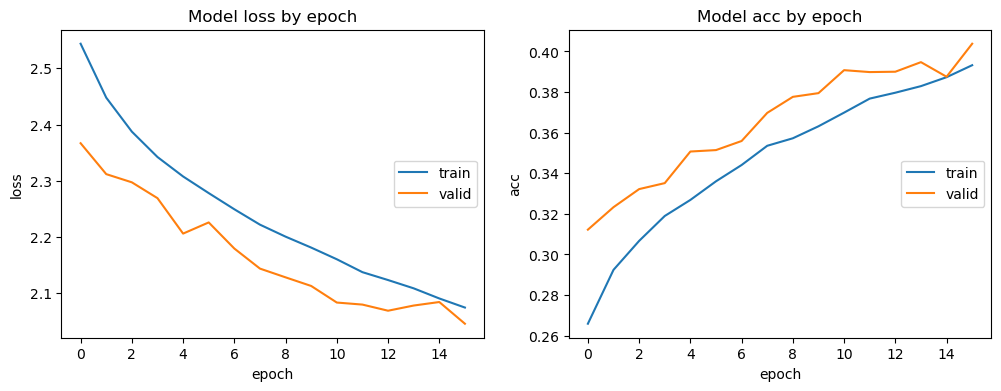

In [32]:
plt.figure(figsize=(12,4))
plt.subplot(121)
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Model loss by epoch')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train', 'valid'], loc='right')

plt.subplot(122)
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('Model acc by epoch')
plt.ylabel('acc')
plt.xlabel('epoch')
plt.legend(['train', 'valid'], loc='right')
plt.show()

#Prediction test_generator

In [35]:
%%time
#Prediction - Valid set
y_pred_proba = model_Densenet.predict(valid_generator)

# l'argmax pour obtenir les classes prédites
y_pred_class = np.argmax(y_pred_proba,axis = 1).astype(int)

# To get classes from test generator
y_true = valid_generator.classes

266/266 [==============================] - 2534s 10s/step
CPU times: total: 58min 29s
Wall time: 42min 14s


#Evaluation - test_generator

In [36]:
%%time
#Get the accuracy score
valid_score = model_Densenet.evaluate(valid_generator)
print("[INFO] Model metrics names:", model_Densenet.metrics_names)
print("[INFO] Accuracy: {:.2f}%".format(valid_score[1] * 100)) 
print("[INFO] Loss: ",valid_score[0])

266/266 [==============================] - 2526s 9s/step - loss: 2.0451 - accuracy: 0.4038
[INFO] Model metrics names: ['loss', 'accuracy']
[INFO] Accuracy: 40.38%
[INFO] Loss:  2.045078992843628
CPU times: total: 59min 21s
Wall time: 42min 6s


In [37]:
f1_macro = f1_score(y_true, y_pred_class, average='macro')
print("[INFO] f1 score macro average: ",f1_macro)

f1_micro = f1_score(y_true, y_pred_class, average='micro')
print("[INFO] f1 score micro average: ",f1_micro)

f1_weighted = f1_score(y_true, y_pred_class, average='weighted')
print("[INFO] f1 score weighted average: ",f1_weighted)

[INFO] f1 score macro average:  0.27885607812240343
[INFO] f1 score micro average:  0.40379180405087134
[INFO] f1 score weighted average:  0.3625278741531103


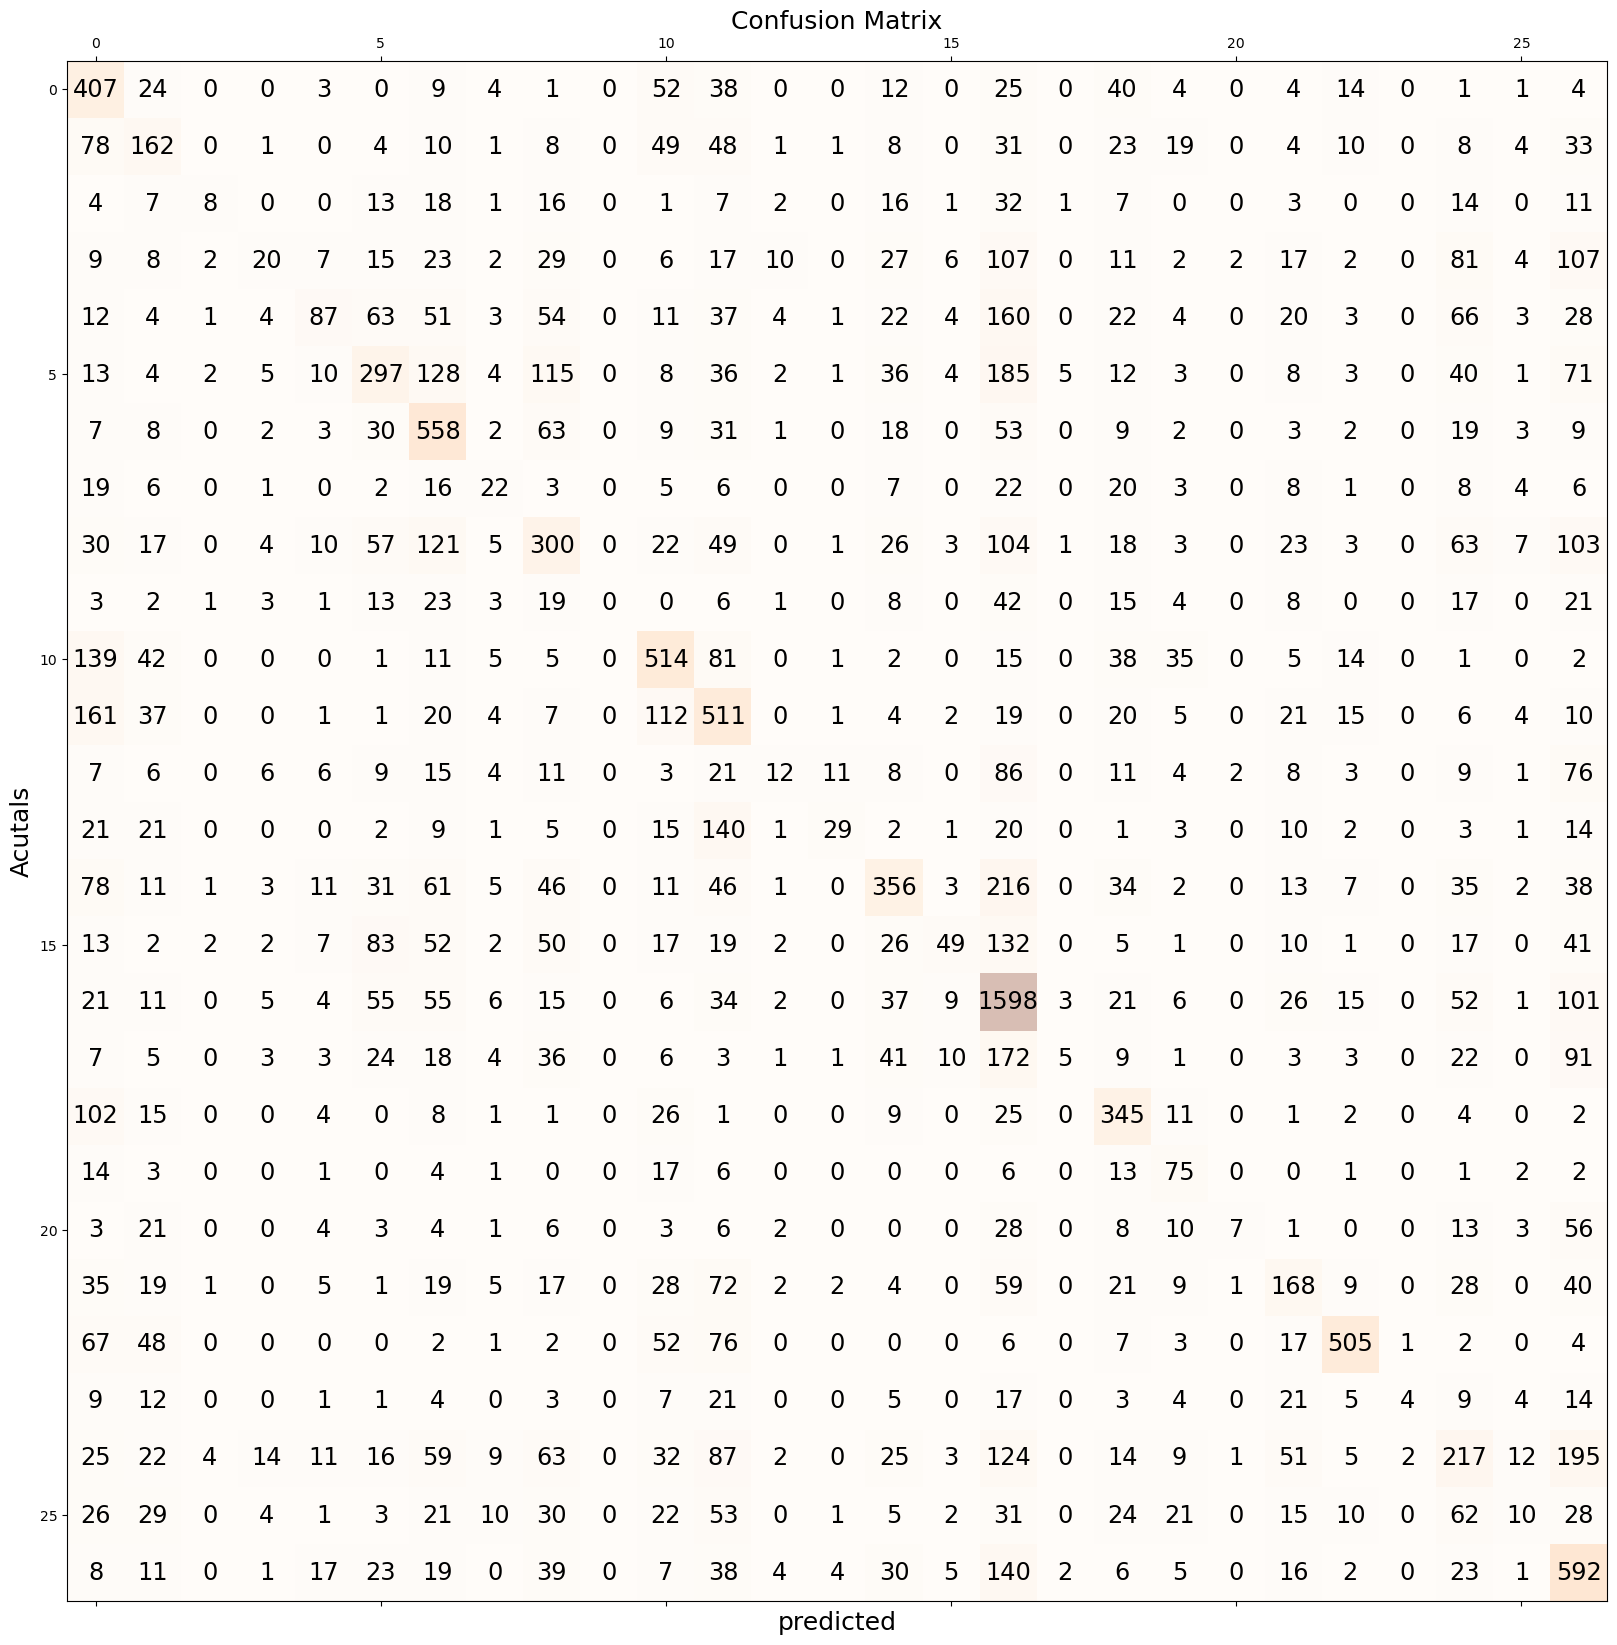

In [38]:
#Confusion matrix
matrix = confusion_matrix(y_true, y_pred_class)
fig , ax = plt.subplots(figsize = (24,20))
ax.matshow(matrix, cmap = plt.cm.Oranges , alpha = 0.3)
for i in range(matrix.shape[0]):
    for j in range (matrix.shape[1]):
        ax.text (x = j , y= i, s= matrix[i,j], va = 'center', ha = 'center', size = 'xx-large')
        
plt.xlabel('predicted', fontsize = 18)
plt.ylabel('Acutals', fontsize = 18)
plt.title('Confusion Matrix', fontsize = 18)
plt.show()
#print(matrix)

In [39]:
print(metrics.classification_report(y_true, y_pred_class))

              precision    recall  f1-score   support

           0       0.31      0.63      0.42       643
           1       0.29      0.32      0.31       503
           2       0.36      0.05      0.09       162
           3       0.26      0.04      0.07       514
           4       0.44      0.13      0.20       664
           5       0.40      0.30      0.34       993
           6       0.42      0.67      0.51       832
           7       0.21      0.14      0.17       159
           8       0.32      0.31      0.31       970
           9       0.00      0.00      0.00       190
          10       0.49      0.56      0.53       911
          11       0.34      0.53      0.42       961
          12       0.24      0.04      0.07       319
          13       0.54      0.10      0.16       301
          14       0.49      0.35      0.41      1011
          15       0.48      0.09      0.15       533
          16       0.46      0.77      0.58      2083
          17       0.29    

C:\Users\yahya\anaconda3\lib\site-packages\sklearn\metrics\_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
C:\Users\yahya\anaconda3\lib\site-packages\sklearn\metrics\_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
C:\Users\yahya\anaconda3\lib\site-packages\sklearn\metrics\_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))


In [63]:
#Enregistrement d'un modèle Keras :
model_Densenet.save("C:\\Users\\yahya\\OneDrive\\Documents\\Rakuten\\DL\\Tensorflow\\Densenet\\DenseNET121_train_img_all_10032024_16_epoch.h5py")


INFO:tensorflow:Assets written to: C:\Users\yahya\OneDrive\Documents\Rakuten\DL\Tensorflow\Densenet\DenseNET121_train_img_all_10032024_16_epoch.h5py\assets


INFO:tensorflow:Assets written to: C:\Users\yahya\OneDrive\Documents\Rakuten\DL\Tensorflow\Densenet\DenseNET121_train_img_all_10032024_16_epoch.h5py\assets


In [ ]:
#Rechargement du modèle :
lenet = load_model("C:\\Users\\yahya\\OneDrive\\Documents\\Rakuten\\Keras\\lenet_train_img_all_10032024_5_epoch.hdf5")